# Perceptron / Single Layer Perceptron Neural Network

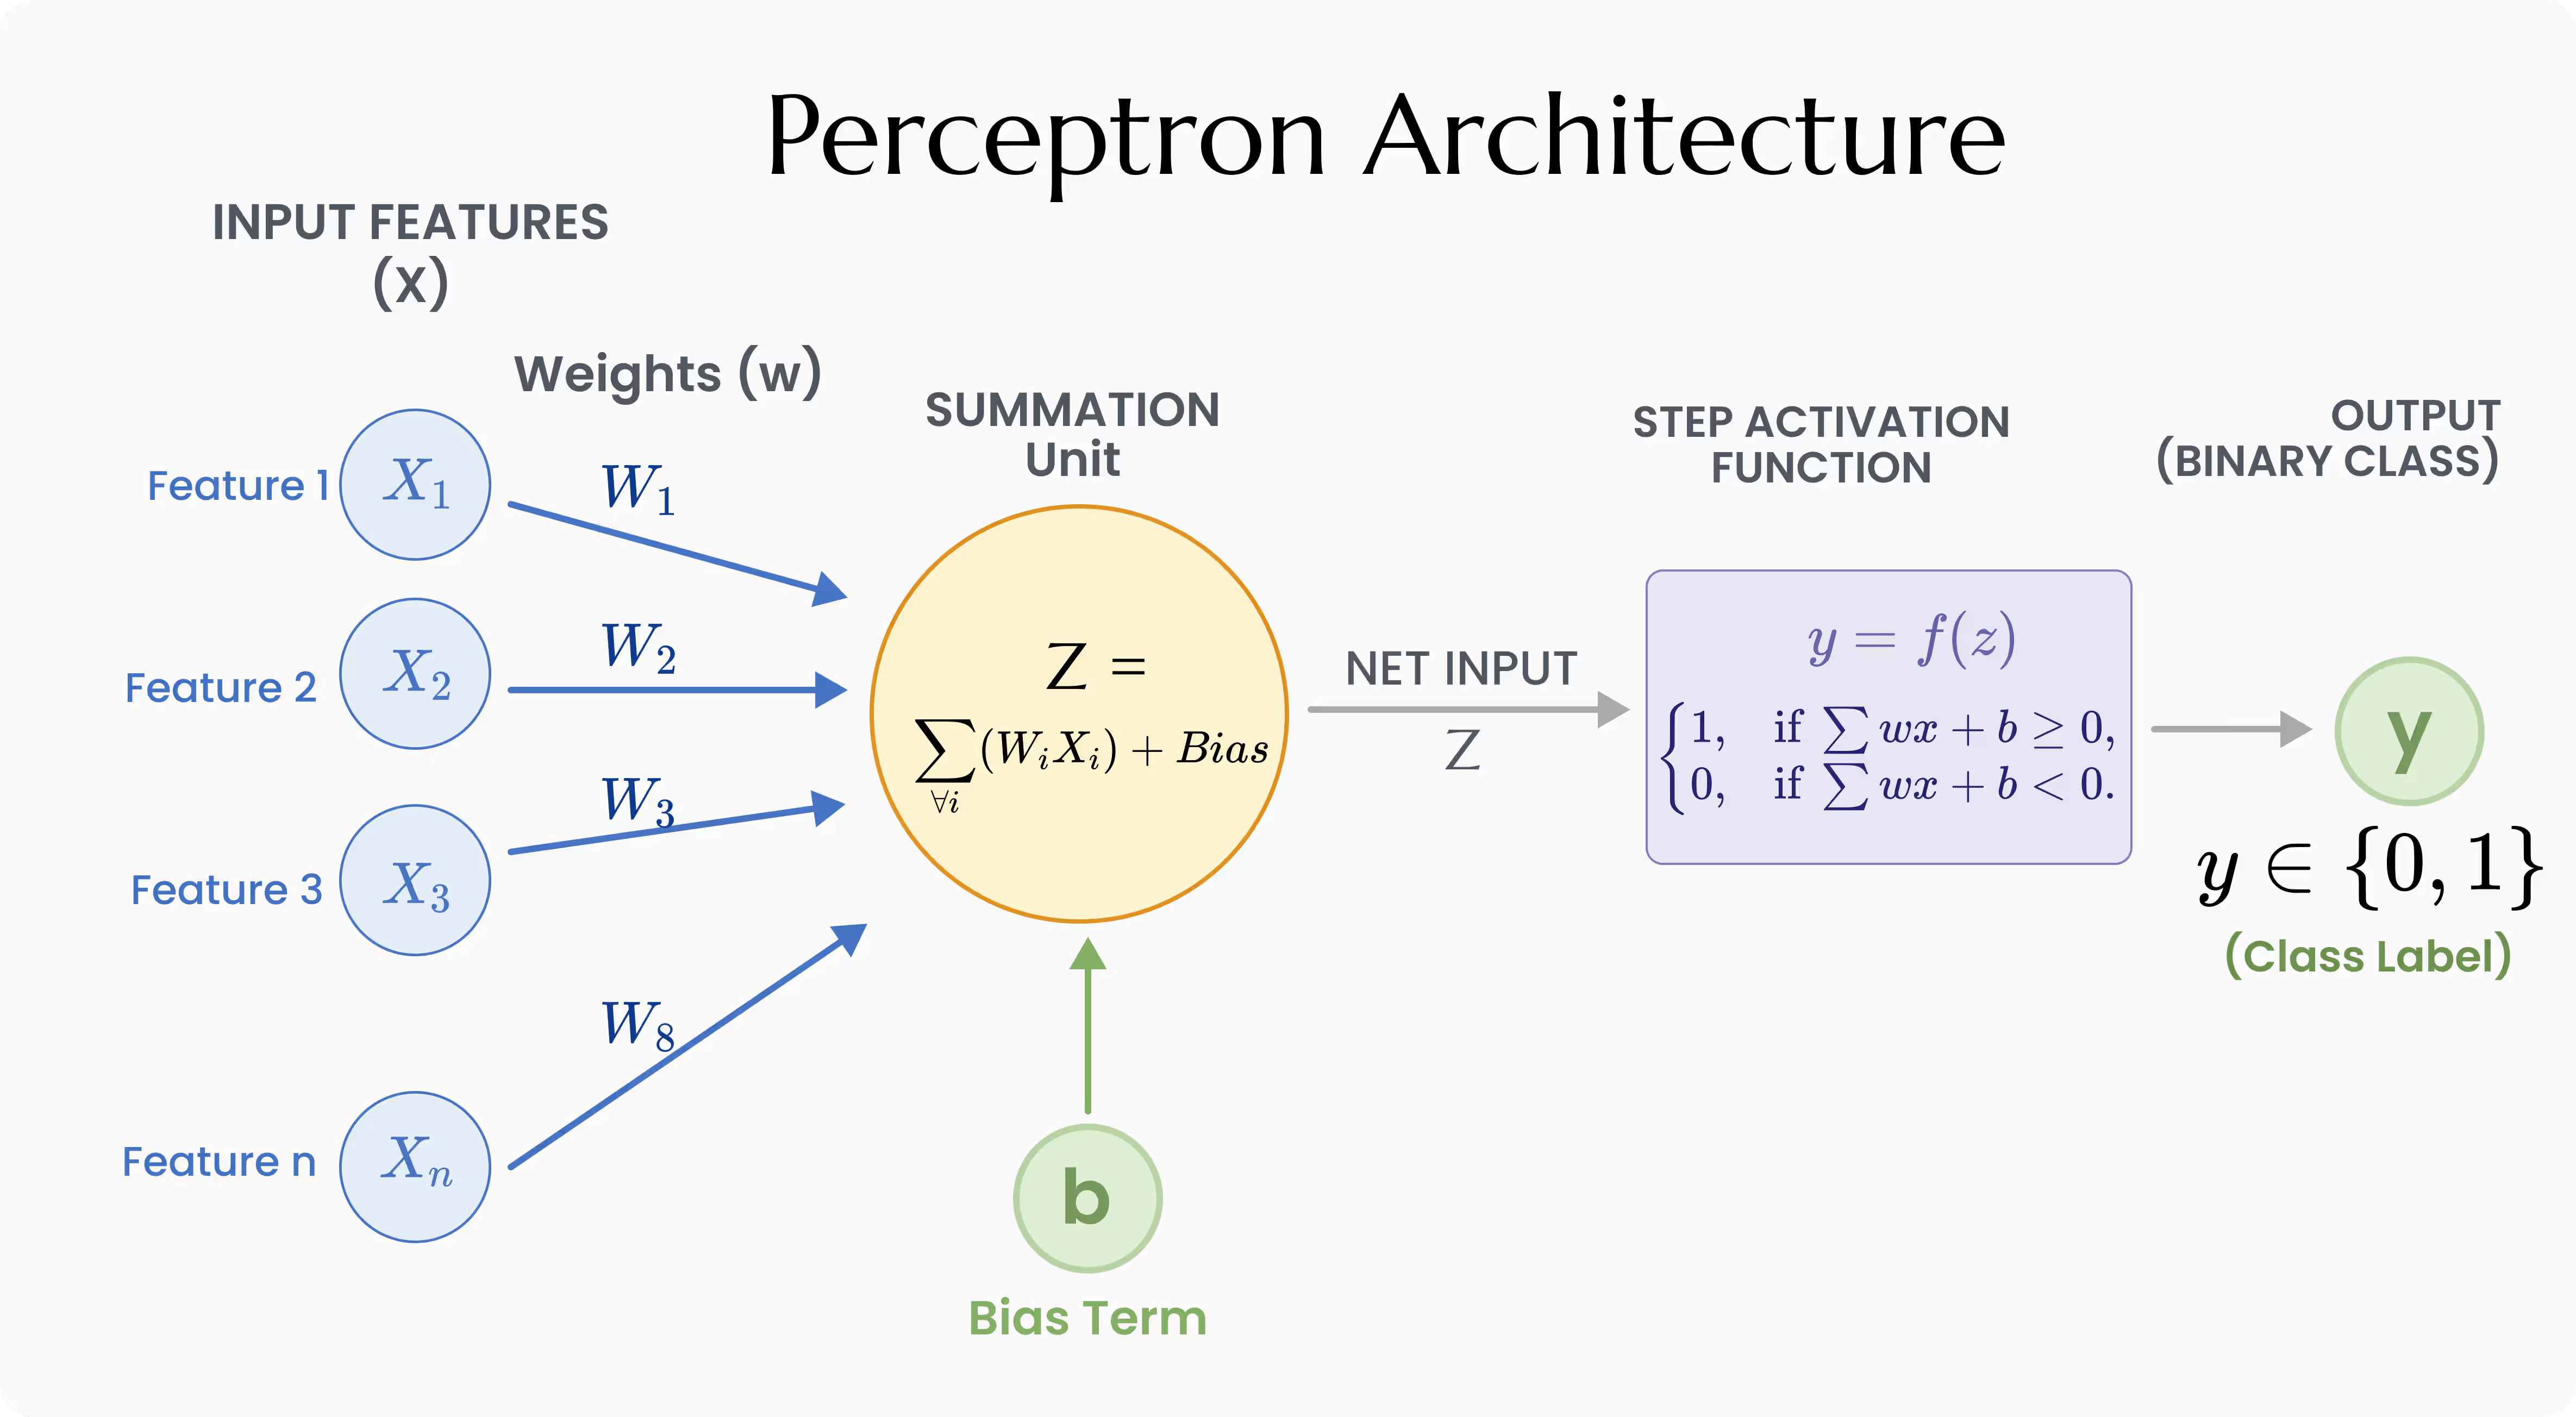

In [32]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

from mpl_toolkits.mplot3d import Axes3D
from sklearn.linear_model import LogisticRegression


In [2]:
inpDir = '../input'
outDir = '../output'

RANDOM_STATE = 24
np.random.seed(RANDOM_STATE)
rng = np.random.default_rng(seed = RANDOM_STATE)

NOISE = 0.2
EPOCHS = 200
ALPHA = 0.001 #lr
N_SAMPLES = 1000 #no of sample to create 
TEST_SIZE = 0.2
CMAP = plt.cm.coolwarm

params = { 'legend.fontsize': 'medium',
           'figure.figsize':(15,6),
           'axes.labelsize':'medium',
           'axes.titlesize':'medium',
           'xtick.labelsize': 'medium',
           'ytick.labelsize': 'medium'
}

In [3]:
datasets?

Type:        module
String form: <module 'sklearn.datasets' from 'C:\\Users\\PGCP-AI.STUDENTSDC\\AppData\\Roaming\\Python\\Python312\\site-packages\\sklearn\\datasets\\__init__.py'>
File:        ~\appdata\roaming\python\python312\site-packages\sklearn\datasets\__init__.py
Docstring:   Utilities to load popular datasets and artificial data generators.

In [4]:
CMAP = plt.colormaps?

Signature:      plt.colormaps()
Type:           ColormapRegistry
String form:   
ColormapRegistry; available colormaps:
           'magma', 'inferno', 'plasma', 'viridis', 'cividis', 'twili <...> , 'tab10_r', 'tab20_r', 'tab20b_r', 'tab20c_r', 'grey_r', 'gist_grey_r', 'gist_yerg_r', 'Grays_r'
Length:         182
File:           ~\appdata\roaming\python\python312\site-packages\matplotlib\cm.py
Docstring:     
Container for colormaps that are known to Matplotlib by name.

The universal registry instance is `matplotlib.colormaps`. There should be
no need for users to instantiate `.ColormapRegistry` themselves.

Read access uses a dict-like interface mapping names to `.Colormap`\s::

    import matplotlib as mpl
    cmap = mpl.colormaps['viridis']

Returned `.Colormap`\s are copies, so that their modification does not
change the global definition of the colormap.

Additional colormaps can be added via `.ColormapRegistry.register`::

    mpl.colormaps.register(my_colormap)

To get a list of

In [5]:
X, y = datasets.make_moons(n_samples=N_SAMPLES,
                           shuffle=True,
                           noise=NOISE,
                           random_state=RANDOM_STATE)
X[:5], y[:5]

(array([[ 0.90633951,  0.90267624],
        [-1.11536828,  0.75579289],
        [ 1.88769158,  0.4175967 ],
        [-0.93345034, -0.02299851],
        [-0.96872877,  0.06396285]]),
 array([0, 0, 1, 0, 0]))

In [6]:
X

array([[ 0.90633951,  0.90267624],
       [-1.11536828,  0.75579289],
       [ 1.88769158,  0.4175967 ],
       ...,
       [ 0.2848561 ,  0.79356025],
       [ 1.7125144 , -0.17778646],
       [-0.95877361,  0.53835778]], shape=(1000, 2))

In [7]:
y

array([0, 0, 1, 0, 0, 0, 1, 0, 1, 1, 0, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0,
       1, 0, 1, 1, 1, 0, 0, 0, 1, 0, 0, 1, 1, 0, 1, 0, 0, 0, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1,
       0, 0, 0, 0, 0, 0, 1, 1, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 1, 1, 0, 0,
       1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0,
       0, 1, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 1, 1, 1, 0, 0, 1, 1, 0, 1, 0,
       1, 0, 1, 1, 0, 1, 1, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 0, 1, 1, 1, 1,
       0, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 0, 0, 1, 0, 0, 1, 1, 1, 1, 0, 1,
       0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 1, 1, 0, 0, 1, 1, 0, 1,
       1, 0, 1, 1, 1, 0, 1, 1, 0, 1, 0, 0, 1, 1, 0, 1, 0, 0, 0, 1, 1, 0,
       0, 0, 1, 1, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1,
       1, 0, 0, 1, 0, 1, 1, 1, 1, 0, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1,
       0, 1, 1, 0, 1, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0,
       1, 0, 1, 0, 0, 0, 1, 0, 1, 1, 0, 0, 0, 0, 0,

In [8]:
df = pd.DataFrame(data=X, columns=['A','B']) #Convert to dataframe
df['target'] = y
df.head()

,A,B,target
0,0.906340,0.902676,0
1,-1.115368,0.755793,0
2,1.887692,0.417597,1
3,-0.933450,-0.022999,0
4,-0.968729,0.063963,0


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   A       1000 non-null   float64
 1   B       1000 non-null   float64
 2   target  1000 non-null   int64  
dtypes: float64(2), int64(1)
memory usage: 23.6 KB


In [10]:
df.describe()

,A,B,target
count,1000.000000,1000.000000,1000.00000
mean,0.490841,0.239025,0.50000
std,0.898951,0.540082,0.50025
min,-1.688795,-0.955280,0.00000
25%,-0.149565,-0.205090,0.00000
50%,0.500100,0.241163,0.50000
75%,1.095048,0.680394,1.00000
max,2.419113,1.612075,1.00000


In [11]:
df.target.unique()

array([0, 1])

<Axes: xlabel='target'>

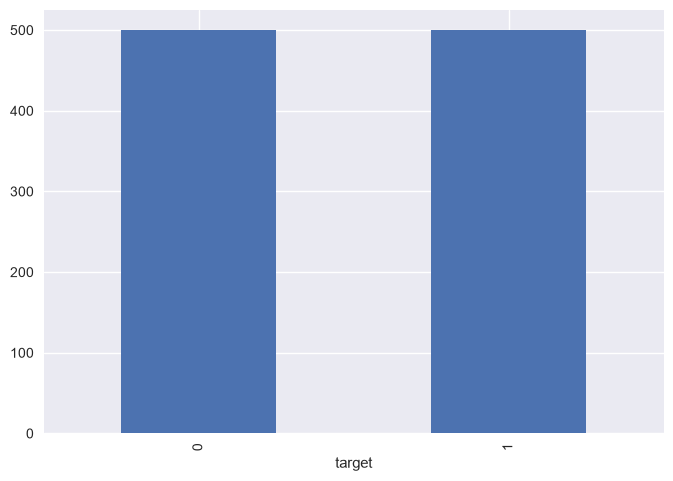

In [12]:
plt.style.use('seaborn-v0_8')
fig, ax = plt.subplots()
df['target'].value_counts().plot(ax=ax, kind='bar')

<Axes: xlabel='A', ylabel='B'>

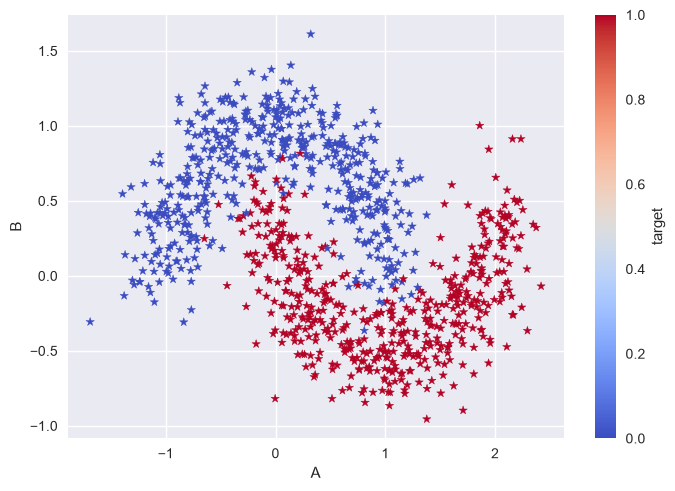

In [13]:
# diff plots
df.plot.scatter('A','B',s=40,marker="*",c='target',cmap='coolwarm')

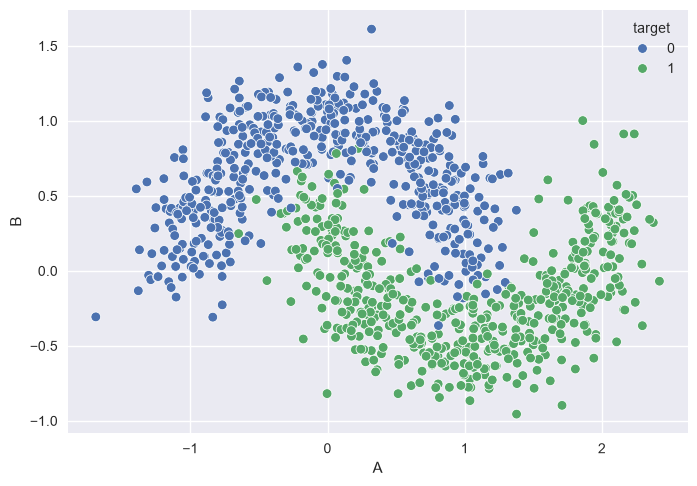

In [14]:
import seaborn as sns
ax = sns.scatterplot(x='A', y='B', data=df, hue="target")

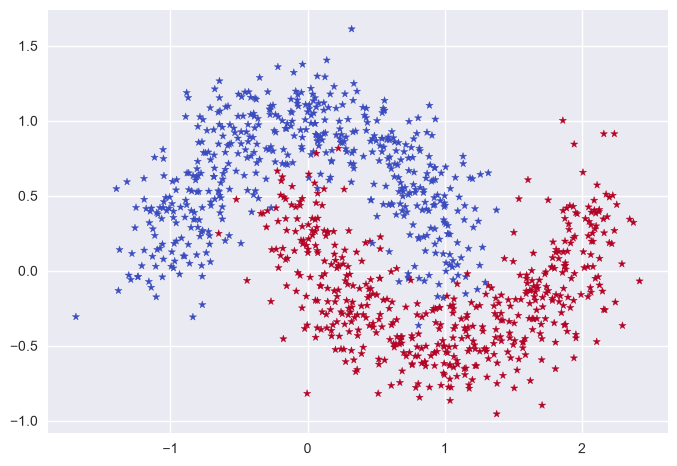

In [15]:
plt.figure()
plt.scatter(X[:,0], X[:,1], s= 30, c=y, marker="*", cmap=CMAP)

In [16]:
print(plt.style.available)

['Solarize_Light2', 'bmh', 'classic', 'dark_background', 'fast', 'fivethirtyeight', 'ggplot', 'grayscale', 'petroff10', 'petroff6', 'petroff8', 'seaborn-v0_8', 'seaborn-v0_8-bright', 'seaborn-v0_8-colorblind', 'seaborn-v0_8-dark', 'seaborn-v0_8-dark-palette', 'seaborn-v0_8-darkgrid', 'seaborn-v0_8-deep', 'seaborn-v0_8-muted', 'seaborn-v0_8-notebook', 'seaborn-v0_8-paper', 'seaborn-v0_8-pastel', 'seaborn-v0_8-poster', 'seaborn-v0_8-talk', 'seaborn-v0_8-ticks', 'seaborn-v0_8-white', 'seaborn-v0_8-whitegrid', 'tableau-colorblind10']


In [17]:
data_train, data_test = df.to_numpy()[:900],df.to_numpy()[900:]
data_train.shape, data_test.shape

((900, 3), (100, 3))

array([0.        , 0.26894142, 0.5       , 0.73105858, 1.        ])

In [73]:
def predict(row: np.ndarray, wgts: np.ndarray):
    '''
    row: one sample of data
    wgts : weight of the model
    '''
    z = wgts[0]

    for i in range(len(row) - 1):
        z += wgts[i+1]*row[i] # agg f()
    return 1 if z >= 0 else 0 # simple activation

In [74]:
weights = np.array([0.1, 0.2, 1.0])

display(df.iloc[0])
predict(df.iloc[0].values, weights)

A         0.906340
B         0.902676
target    0.000000
Name: 0, dtype: float64

1

In [75]:
weights = np.array([0.1,2.0,1.0])

In [76]:
rng.standard_normal([data_train.shape[1]])

array([ 0.96665533, -1.12796069, -0.18845853])

In [78]:
def train_weights(train : np.ndarray, alpha : float, n_epochs : int) -> tuple[list, np.ndarray]:
    errors = [] #collect all errors
    wights = rng.random(train.shape[1]) # random generation
    m = train.shape[0] #num samples

    for epochs in range(n_epochs):
        sum_error = 0.0
        for row in train:
            prediction = predict(row, weights)
            error = prediction - row[-1]
            sum_error += error**2
            weights[0] = weights[0] - alpha*error #adjusting weights
            for i in range(len(row) -1):
                weights[i+1] = weights[i+1] - alpha*error*row[i] # adjusting weights
        errors.append(sum_error/m)
        if epochs % 10 == 0:
            print(f"Epochs {epochs:3d}: Loss = {errors[-1]:.4f}")
    return errors, weights

In [79]:
errors, weights = train_weights(data_train, ALPHA, EPOCHS)
display(weights)

Epochs   0: Loss = 0.3633
Epochs  10: Loss = 0.3033
Epochs  20: Loss = 0.1433
Epochs  30: Loss = 0.1678
Epochs  40: Loss = 0.1778
Epochs  50: Loss = 0.1722
Epochs  60: Loss = 0.1722
Epochs  70: Loss = 0.1722
Epochs  80: Loss = 0.1800
Epochs  90: Loss = 0.1800
Epochs 100: Loss = 0.1856
Epochs 110: Loss = 0.1722
Epochs 120: Loss = 0.1722
Epochs 130: Loss = 0.1722
Epochs 140: Loss = 0.1778
Epochs 150: Loss = 0.1678
Epochs 160: Loss = 0.1789
Epochs 170: Loss = 0.1722
Epochs 180: Loss = 0.1700
Epochs 190: Loss = 0.1700


array([-6.93889390e-18,  2.19961152e-03, -4.93106708e-03])

In [80]:
display(errors)

[np.float64(0.36333333333333334),
 np.float64(0.37),
 np.float64(0.3844444444444444),
 np.float64(0.37666666666666665),
 np.float64(0.3688888888888889),
 np.float64(0.3622222222222222),
 np.float64(0.35555555555555557),
 np.float64(0.34444444444444444),
 np.float64(0.3277777777777778),
 np.float64(0.31444444444444447),
 np.float64(0.30333333333333334),
 np.float64(0.2866666666666667),
 np.float64(0.27555555555555555),
 np.float64(0.2644444444444444),
 np.float64(0.24888888888888888),
 np.float64(0.23),
 np.float64(0.2111111111111111),
 np.float64(0.1922222222222222),
 np.float64(0.17333333333333334),
 np.float64(0.15333333333333332),
 np.float64(0.14333333333333334),
 np.float64(0.13666666666666666),
 np.float64(0.14333333333333334),
 np.float64(0.14333333333333334),
 np.float64(0.14444444444444443),
 np.float64(0.14444444444444443),
 np.float64(0.14333333333333334),
 np.float64(0.14222222222222222),
 np.float64(0.1411111111111111),
 np.float64(0.1411111111111111),
 np.float64(0.167777

# Plot Errors

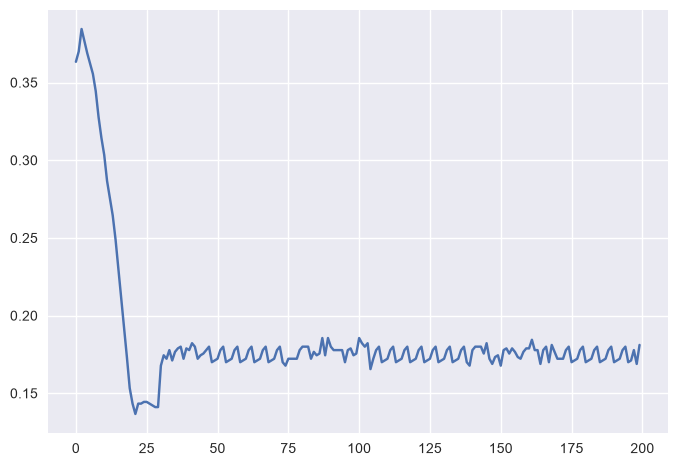

In [81]:
fig, ax = plt.subplots()
ax.plot(errors)

# Make Prediction

In [82]:
prediction = []

for row in data_train:
    a = predict(row, weights)
    prediction.append(a)

accuracy_score(data_train[:,-1],prediction)

0.8611111111111112

In [83]:
prediction = []

for row in data_test:
    a = predict(row, weights)
    prediction.append(a)

accuracy_score(data_test[:,-1],prediction)

0.9

In [84]:
cm = confusion_matrix(data_test[:,-1], prediction)
cm

array([[54,  4],
       [ 6, 36]])

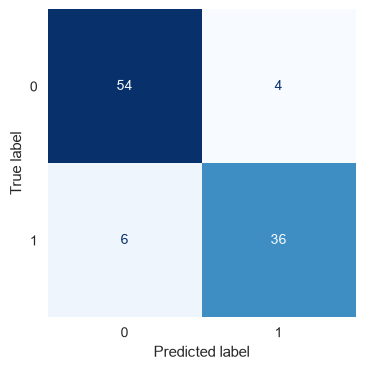

In [85]:
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0,1])
fig, ax = plt.subplots(figsize=(4,4))
disp.plot(ax=ax,cmap='Blues',colorbar=False)
plt.grid()

In [86]:
def plot_decision_boundary(X_tr, X_ts, wts):
    fig, ax = plt.subplots()
    dm = 0.01
    margin = 10*dm
    x_min, x_max = X_tr[:,0].min() - margin, X_tr[:,0].max() -margin
    y_min, y_max = X_tr[:,1].min() - margin, X_tr[:,1].max() -margin
    
    xx, yy = np.meshgrid(np.arange(x_min, x_max, dm),
                        np.arange(x_min, x_max, dm))

    XX = np.c_[xx.ravel(), yy.ravel()]
    XX = np.hstack((XX, np.ones((XX.shape[0], 1))))

    y_pred = []
    
    for row in XX:
        a = predict(row, wts)
        y_pred.append(a)
    Z = np.array(y_pred).reshape(xx.shape)
    ax.contourf(xx, yy, Z, cmap=plt.cm.Paired, alpha=0.6)
    ax.scatter(X_tr[:,0], X_tr[:,1], c = X_tr[:,2], s = 30, edgecolors='k',cmap=CMAP)
    ax.scatter(X_ts[:,0], X_ts[:,1], c = X_ts[:,2], s = 30, edgecolors='k',cmap=CMAP)

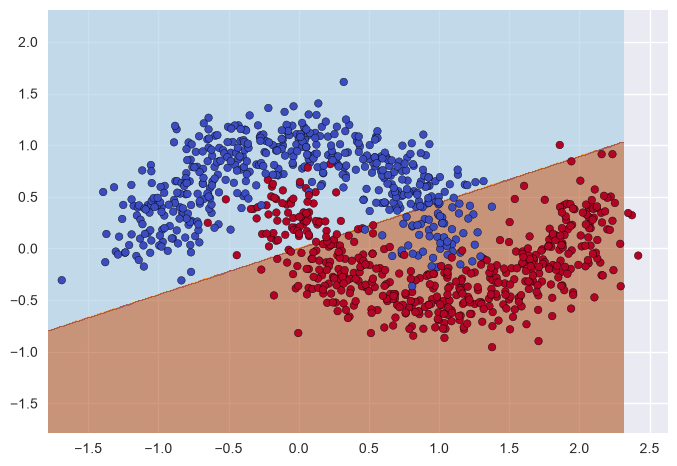

In [87]:
plot_decision_boundary(data_train, data_test, weights)